# 03 — Interaction states

Exploratory state discovery on all participants (the evaluation refits the
scaler and HMM inside each training fold, per proposal §3.8).

Run `make data` and `make states` first.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
states_dir = ROOT / "artifacts" / "states"

selection = pd.read_csv(states_dir / "state_selection.csv")
profiles = pd.read_csv(states_dir / "state_profiles.csv")
matrix = pd.read_csv(states_dir / "state_transition_matrix.csv", index_col=0)
manifest = json.loads((states_dir / "state_manifest.json").read_text())
manifest["n_states"], manifest["selected_by"]

(4,
 'elbow: adding the next state improves median BIC by less than 10% of the total gain')

## BIC across candidate state counts

BIC often keeps falling on large continuous datasets. The selection rule is
recorded in `docs/DECISIONS.md`: use an interior minimum when it exists; when
it does not, stop where another state adds less than 10% of the total BIC gain.

{'runs': 5, 'mean_ari': 0.9346605566335355, 'min_ari': 0.836651391583839, 'pairwise_ari': [0.836651391583839, 1.0, 1.0, 1.0, 0.836651391583839, 0.836651391583839, 0.836651391583839, 1.0, 1.0, 1.0]}


n_states
2     2427.1
3   -10258.0
4   -15369.9
5   -16877.7
6   -18874.7
Name: bic, dtype: float64

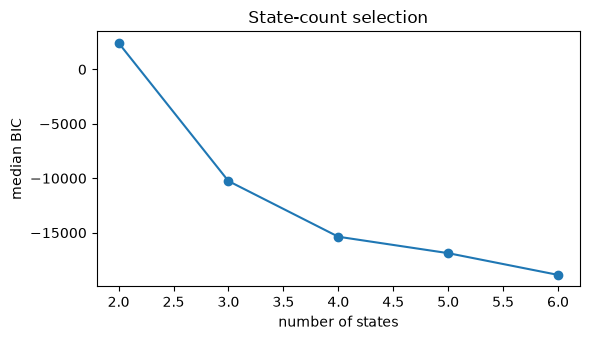

In [2]:
medians = selection.groupby("n_states")["bic"].median()
ax = medians.plot(marker="o", figsize=(6, 3.5))
ax.set_xlabel("number of states")
ax.set_ylabel("median BIC")
ax.set_title("State-count selection")
plt.tight_layout()

print(manifest["stability"])
medians.round(1)

## State profiles

Labels are descriptive, assigned from the state means (highest typing, then
switching, then idle, then mouse activity).

In [3]:
display(profiles.round(2))

,state,epochs,share,typing_rate,idle_ratio,mouse_speed_px_s,switch_rate,label
0,0,3303,0.50,1.21,0.95,8.30,0.12,Idle / away
1,1,1720,0.26,69.10,0.43,139.02,2.20,Sustained typing
2,2,812,0.12,12.50,0.44,183.74,2.68,Browsing / light activity
3,3,765,0.12,3.87,0.88,22.87,2.83,Frequent switching


## Transition probabilities

Rows sum to 1. High diagonal values mean the state is persistent; the
off-diagonal ones show interruption and recovery paths.

In [4]:
display(matrix.round(3))

,0 · Idle / away,1 · Sustained typing,2 · Browsing / light activity,3 · Frequent switching
0 · Idle / away,0.978,0.000,0.022,0.000
1 · Sustained typing,0.000,0.871,0.030,0.099
2 · Browsing / light activity,0.088,0.054,0.785,0.072
3 · Frequent switching,0.000,0.219,0.073,0.708


## One session over time

Each block is one minute. This is the raw material for the dwell, interruption
and recovery features used by the models.

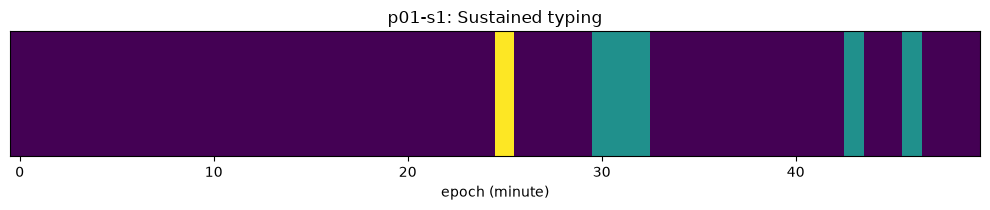

In [5]:
sequences = pd.read_csv(ROOT / "data" / "processed" / "state_sequences.csv")
session_id = sequences["session_id"].iloc[0]
sample = sequences[sequences["session_id"] == session_id]

fig, ax = plt.subplots(figsize=(10, 2.2))
ax.imshow([sample["state"].to_numpy()], aspect="auto", cmap="viridis")
ax.set_yticks([])
ax.set_xlabel("epoch (minute)")
ax.set_title(f"{session_id}: {sample['state_label'].iloc[0].split(' /')[0]}")
plt.tight_layout()

## Before using these states

- Refit the scaler and HMM on training participants only.
- Report stability (adjusted Rand index across seeds); low stability means the
  state count is not supported by the data.
- Keep the state id and label out of the label leakage path: they are features,
  never targets.